In [11]:
import pandas as pd

orders = pd.read_csv('olist_orders_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

print("Orders shape:", orders.shape)
print("Order items shape:", order_items.shape)
orders.head()

Orders shape: (99441, 8)
Order items shape: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
import os
print("Current folder:", os.getcwd())
print("Files here:", os.listdir())

Current folder: /content
Files here: ['.config', 'sample_data']


In [10]:
from google.colab import files
uploaded = files.upload()

Saving olist_customers_dataset.csv to olist_customers_dataset.csv


In [12]:
# Merge order_items with products to get category info
merged = order_items.merge(products, on='product_id', how='left')

# Merge with orders to filter only delivered orders
merged = merged.merge(orders[['order_id', 'order_status']], on='order_id', how='left')
merged = merged[merged['order_status'] == 'delivered']

# Revenue by product category
category_revenue = merged.groupby('product_category_name')['price'].sum().sort_values(ascending=False)

print("Top 10 categories by revenue:")
category_revenue.head(10)

Top 10 categories by revenue:


,price
product_category_name,
beleza_saude,1233131.72
relogios_presentes,1166176.98
cama_mesa_banho,1023434.76
esporte_lazer,954852.55
informatica_acessorios,888724.61
moveis_decoracao,711927.69
utilidades_domesticas,615628.69
cool_stuff,610204.10
automotivo,578966.65


In [13]:
 # Load the English translation file
translation = pd.read_csv('product_category_name_translation.csv')

# Merge to get English category names
merged = merged.merge(translation, on='product_category_name', how='left')

category_revenue_en = merged.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top 10 categories by revenue (English):")
category_revenue_en.head(10)

Top 10 categories by revenue (English):


,price
product_category_name_english,
health_beauty,1233131.72
watches_gifts,1166176.98
bed_bath_table,1023434.76
sports_leisure,954852.55
computers_accessories,888724.61
furniture_decor,711927.69
housewares,615628.69
cool_stuff,610204.10
auto,578966.65


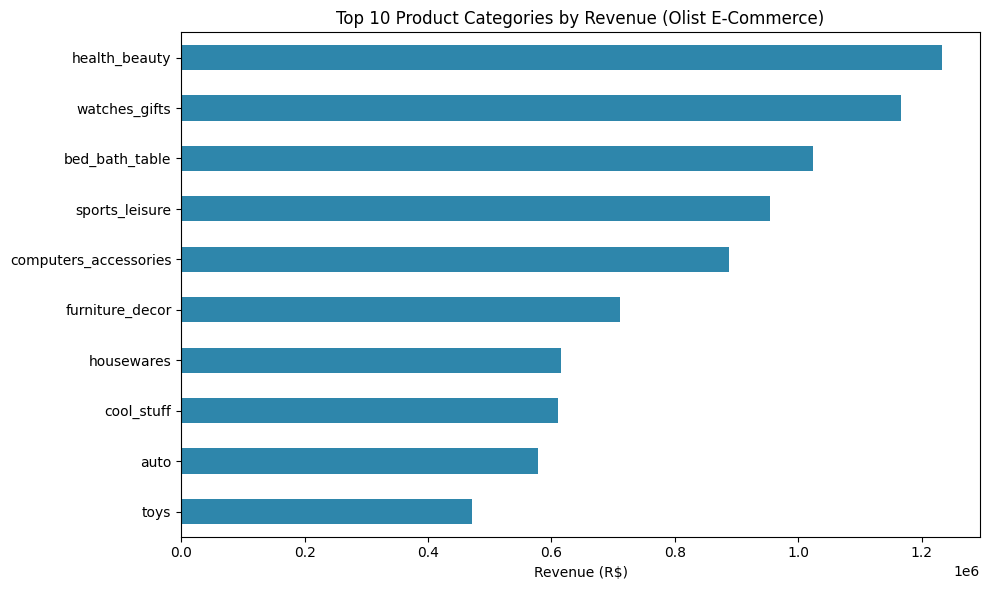

In [14]:
import matplotlib.pyplot as plt

top10 = category_revenue_en.head(10)

plt.figure(figsize=(10,6))
top10.sort_values().plot(kind='barh', color='#2E86AB')
plt.title('Top 10 Product Categories by Revenue (Olist E-Commerce)')
plt.xlabel('Revenue (R$)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('top_categories_revenue.png', dpi=150)
plt.show()

In [15]:
# Convert date columns to datetime
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

# Calculate delivery delay in days (positive = late, negative = early)
orders['delivery_delay_days'] = (orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']).dt.days

delivered = orders[orders['order_status'] == 'delivered']

late_pct = (delivered['delivery_delay_days'] > 0).mean() * 100
avg_delay = delivered[delivered['delivery_delay_days'] > 0]['delivery_delay_days'].mean()

print(f"% of orders delivered late: {late_pct:.1f}%")
print(f"Average delay when late: {avg_delay:.1f} days")
print(f"\nDelivery delay distribution:")
delivered['delivery_delay_days'].describe()

% of orders delivered late: 6.8%
Average delay when late: 10.6 days

Delivery delay distribution:


,delivery_delay_days
count,96470.000000
mean,-11.875889
std,10.182105
min,-147.000000
25%,-17.000000
50%,-12.000000
75%,-7.000000
max,188.000000


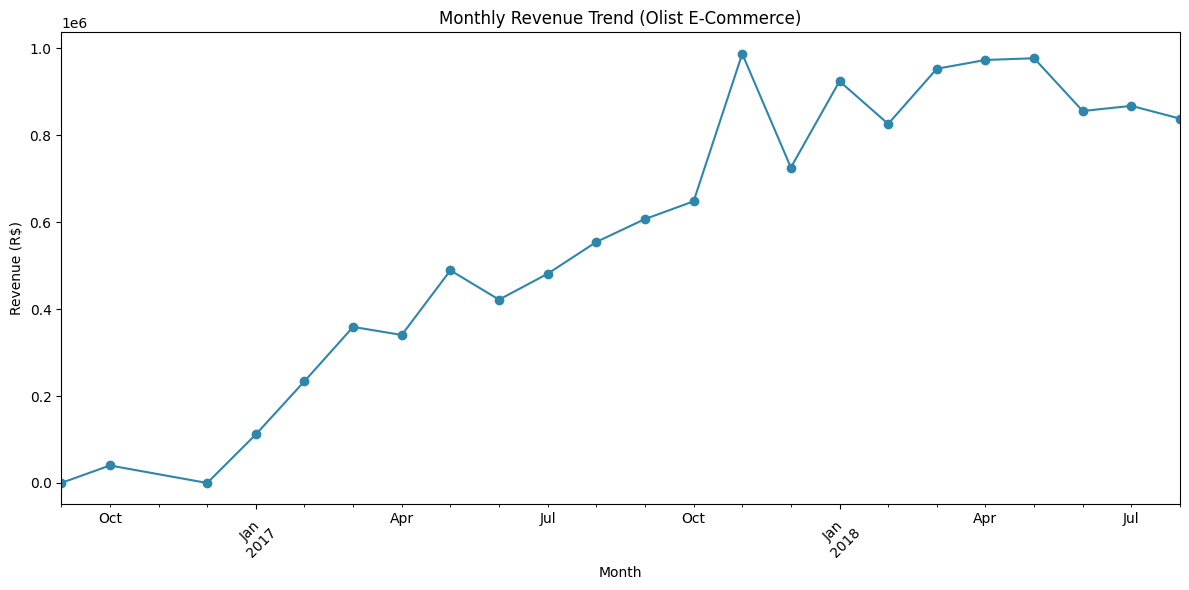

In [16]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

# Merge orders with order_items to get revenue per order
revenue_by_order = order_items.merge(orders[['order_id', 'order_month', 'order_status']], on='order_id')
revenue_by_order = revenue_by_order[revenue_by_order['order_status'] == 'delivered']

monthly_revenue = revenue_by_order.groupby('order_month')['price'].sum()

plt.figure(figsize=(12,6))
monthly_revenue.plot(kind='line', marker='o', color='#2E86AB')
plt.title('Monthly Revenue Trend (Olist E-Commerce)')
plt.xlabel('Month')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_revenue_trend.png', dpi=150)
plt.show()

In [17]:
from google.colab import files
files.download('top_categories_revenue.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
files.download('monthly_revenue_trend.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>